# Exercise P10.1: Cross-Validation in scikit-learn
### STAT 540 — Week 10


## Overview

Use cross-validation to tune k-NN in scikit-learn and compare to a decision tree.

## Task 1: CV Accuracy vs k

Best k: 5, CV accuracy: 0.910


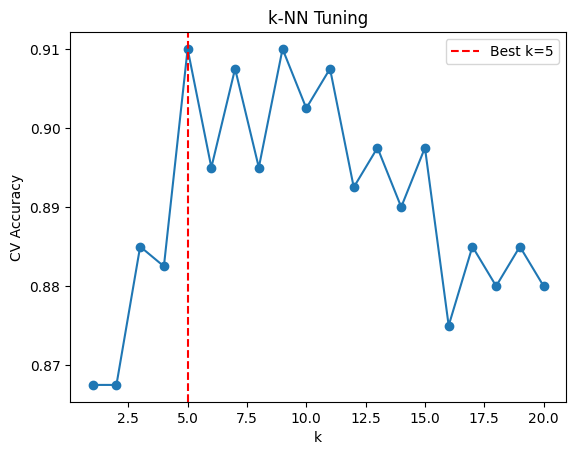

In [2]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.datasets import make_classification
import numpy as np
import matplotlib.pyplot as plt

# --- Generate a synthetic dataset for demonstration ---
X, y = make_classification(n_samples=500, n_features=10, n_informative=5, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
# ------------------------------------------------------

ks = range(1, 21)
scores = [cross_val_score(
    Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsClassifier(n_neighbors=k))]),
    X_train, y_train, cv=5
).mean() for k in ks]

best_k = ks[int(np.argmax(scores))]
print(f"Best k: {best_k}, CV accuracy: {max(scores):.3f}")

plt.plot(ks, scores, marker="o")
plt.xlabel("k"); plt.ylabel("CV Accuracy"); plt.title("k-NN Tuning")
plt.axvline(best_k, color="red", linestyle="--", label=f"Best k={best_k}")
plt.legend(); plt.show()

> CV accuracy is lowest at k = 1 to 2 (about 0.867), where the model overfits to individual points. It rises to a peak of 0.910 at k = 5, stays around 0.90 to 0.91 through around k = 11, then declines at larger k (down to 0.875 at k = 16) as the model oversmooths. The best k is 5, but with only 400 training rows the differences among k = 5 to 11 are within fold-to-fold noise, so any k in that range would be reasonable.

## Task 2: Compare k-NN vs Decision Tree

In [3]:
from sklearn.tree import DecisionTreeClassifier

# Decision tree with CV
tree_scores = cross_val_score(
    DecisionTreeClassifier(max_depth=5, random_state=42),
    X_train, y_train, cv=5
)
print(f"Decision Tree CV: {tree_scores.mean():.3f} +/- {tree_scores.std():.3f}")
print(f"Best k-NN CV:     {max(scores):.3f}")

Decision Tree CV: 0.865 +/- 0.032
Best k-NN CV:     0.910


**Your turn:** Which model performs better? What are the tradeoffs?

> The tuned k-NN (CV accuracy 0.910) outperformed the depth-5 decision tree (0.865 ± 0.032). The 0.045 gap is larger than the tree’s fold-to-fold SD, so k-NN appears better on this data. The main caveats are that the k-NN score is the best of 20 values and is slightly optimistic, and the tree’s depth was not tuned. Therefore, the final comparison should use the held-out test set, which hasn’t been touched yet.

## Task 3: Final Test Evaluation

In [4]:
from sklearn.metrics import classification_report

best_pipe = Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsClassifier(n_neighbors=best_k))])
best_pipe.fit(X_train, y_train)
print(classification_report(y_test, best_pipe.predict(X_test)))

              precision    recall  f1-score   support

           0       0.83      0.90      0.87        50
           1       0.89      0.82      0.85        50

    accuracy                           0.86       100
   macro avg       0.86      0.86      0.86       100
weighted avg       0.86      0.86      0.86       100



## Submission

```bash
git add week10/exercises/P10.1*
git commit -m "Complete Exercise P10.1: Cross-validation and model comparison"
git push origin main
```